# CNN

In [23]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

from tensorflow.keras import layers
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Dense, Dropout, BatchNormalization,
    Conv2D, MaxPooling2D, Flatten
)
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.utils import load_img, img_to_array

from sklearn.metrics import confusion_matrix, classification_report

import joblib

In [44]:
import warnings
warnings.filterwarnings('ignore')

In [24]:
#(x_train, y_train), (x_test, y_test) = cifar10.load_data()  --> takes too long to download

# https://data.brainchip.com/dataset-mirror/cifar10/   --> download from here and extract it in your code folder and run the below code cell 

In [26]:
import pickle
import os
import numpy as np

cifar_path = r"cifar-10-batches-py"

def load_batch(file_path):
    with open(file_path, "rb") as f:
        batch = pickle.load(f, encoding="bytes")

    X = batch[b"data"]
    y = batch[b"labels"]

    return X, y

x_train_list = []
y_train_list = []

for i in range(1, 6):
    X, y = load_batch(
        os.path.join(cifar_path, f"data_batch_{i}")
    )

    x_train_list.append(X)
    y_train_list.extend(y)

x_train = np.concatenate(x_train_list)
y_train = np.array(y_train_list).reshape(-1, 1)

x_test, y_test = load_batch(
    os.path.join(cifar_path, "test_batch")
)

y_test = np.array(y_test).reshape(-1, 1)

x_train = x_train.reshape(-1, 3, 32, 32)
x_train = x_train.transpose(0, 2, 3, 1)

x_test = x_test.reshape(-1, 3, 32, 32)
x_test = x_test.transpose(0, 2, 3, 1)

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("x_train:", x_train.shape)
print("y_train:", y_train.shape)
print("x_test :", x_test.shape)
print("y_test :", y_test.shape)

x_train: (50000, 32, 32, 3)
y_train: (50000, 1)
x_test : (10000, 32, 32, 3)
y_test : (10000, 1)


In [27]:
print("Training Data Shape:", x_train.shape)
print("Testing Data Shape:", x_test.shape)

print("Number of Training Images:", x_train.shape[0])
print("Number of Testing Images:", x_test.shape[0])

print("First Image:")
print(x_train[0])

Training Data Shape: (50000, 32, 32, 3)
Testing Data Shape: (10000, 32, 32, 3)
Number of Training Images: 50000
Number of Testing Images: 10000
First Image:
[[[0.23137255 0.24313726 0.24705882]
  [0.16862746 0.18039216 0.1764706 ]
  [0.19607843 0.1882353  0.16862746]
  ...
  [0.61960787 0.5176471  0.42352942]
  [0.59607846 0.49019608 0.4       ]
  [0.5803922  0.4862745  0.40392157]]

 [[0.0627451  0.07843138 0.07843138]
  [0.         0.         0.        ]
  [0.07058824 0.03137255 0.        ]
  ...
  [0.48235294 0.34509805 0.21568628]
  [0.46666667 0.3254902  0.19607843]
  [0.47843137 0.34117648 0.22352941]]

 [[0.09803922 0.09411765 0.08235294]
  [0.0627451  0.02745098 0.        ]
  [0.19215687 0.10588235 0.03137255]
  ...
  [0.4627451  0.32941177 0.19607843]
  [0.47058824 0.32941177 0.19607843]
  [0.42745098 0.28627452 0.16470589]]

 ...

 [[0.8156863  0.6666667  0.3764706 ]
  [0.7882353  0.6        0.13333334]
  [0.7764706  0.6313726  0.10196079]
  ...
  [0.627451   0.52156866 0.274

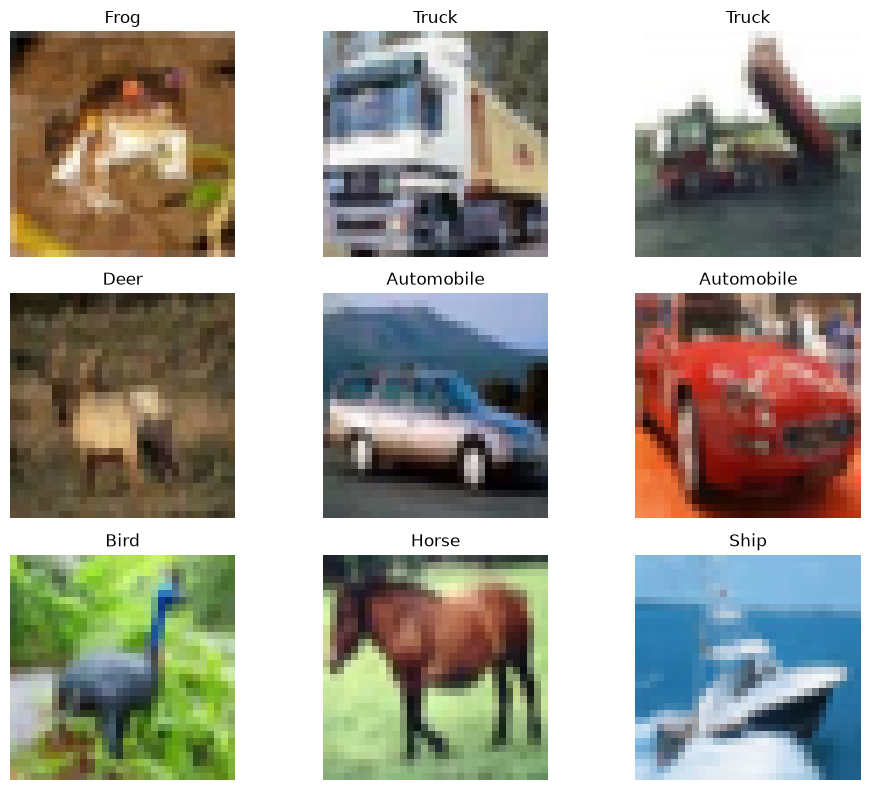

In [28]:
class_names = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]

plt.figure(figsize=(10, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[int(y_train[i][0])])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [29]:
y_train = to_categorical(y_train, num_classes=10)
y_test = to_categorical(y_test, num_classes=10)

In [30]:
train_norm = x_train.astype('float32')
test_norm = x_test.astype('float32')

train_norm = train_norm / 255.0
test_norm = test_norm / 255.0

In [31]:
model = Sequential()

model.add(keras.Input(shape=(32, 32, 3)))

model.add(Conv2D(32, (3, 3), activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D((2, 2)))

model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D((2, 2)))

model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D((2, 2)))

model.add(Flatten())

model.add(Dense(100, activation='relu'))
model.add(BatchNormalization())

model.add(Dense(10, activation='softmax'))

In [32]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 30, 30, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 13, 13, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 4, 4, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 2, 2, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 100)            │        25,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 100)            │           400 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 84,070 (328.40 KB)

 Trainable params: 83,550 (326.37 KB)

 Non-trainable params: 520 (2.03 KB)

In [33]:
m2 = model.fit(
    train_norm,
    y_train,
    epochs=10,
    batch_size=100,
    validation_split=0.1
)

Epoch 1/10
450/450 ━━━━━━━━━━━━━━━━━━━━ 34s 69ms/step - accuracy: 0.4883 - loss: 1.4493 - val_accuracy: 0.0976 - val_loss: 3.9961
Epoch 2/10
450/450 ━━━━━━━━━━━━━━━━━━━━ 32s 71ms/step - accuracy: 0.6086 - loss: 1.1096 - val_accuracy: 0.1390 - val_loss: 4.7619
Epoch 3/10
450/450 ━━━━━━━━━━━━━━━━━━━━ 33s 73ms/step - accuracy: 0.6652 - loss: 0.9592 - val_accuracy: 0.2312 - val_loss: 7.1366
Epoch 4/10
450/450 ━━━━━━━━━━━━━━━━━━━━ 32s 71ms/step - accuracy: 0.6977 - loss: 0.8680 - val_accuracy: 0.0986 - val_loss: 9.4915
Epoch 5/10
450/450 ━━━━━━━━━━━━━━━━━━━━ 32s 72ms/step - accuracy: 0.7238 - loss: 0.7897 - val_accuracy: 0.1682 - val_loss: 10.2632
Epoch 6/10
450/450 ━━━━━━━━━━━━━━━━━━━━ 32s 71ms/step - accuracy: 0.7455 - loss: 0.7283 - val_accuracy: 0.1070 - val_loss: 14.3449
Epoch 7/10
450/450 ━━━━━━━━━━━━━━━━━━━━ 32s 71ms/step - accuracy: 0.7615 - loss: 0.6821 - val_accuracy: 0.0976 - val_loss: 30.2378
Epoch 8/10
450/450 ━━━━━━━━━━━━━━━━━━━━ 32s 71ms/step - accuracy: 0.7793 - loss: 0.6305

In [34]:
test_loss, test_accuracy = model.evaluate(
    test_norm,
    y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.1000 - loss: 34.3908
Test Loss: 34.39077377319336
Test Accuracy: 0.10000000149011612


In [35]:
pred = model.predict(test_norm)

print("First Prediction:", pred[0])

print("Predicted Class:", np.argmax(pred[0]))

print("Actual Class:", np.argmax(y_test[0]))

print("Predicted Label:", class_names[np.argmax(pred[0])])

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
First Prediction: [8.7875973e-09 9.9999654e-01 2.8710330e-09 2.7240996e-20 1.5739122e-37
 4.6694589e-14 8.2278344e-20 1.4103734e-28 3.4867471e-06 4.0342392e-15]
Predicted Class: 1
Actual Class: 3
Predicted Label: Automobile


In [36]:
y_pred = np.argmax(pred, axis=1)
y_actual = np.argmax(y_test, axis=1)

cm = confusion_matrix(y_actual, y_pred)

print("Confusion Matrix:")
print(cm)

print(classification_report(
    y_actual,
    y_pred,
    target_names=class_names
))

Confusion Matrix:
[[   0 1000    0    0    0    0    0    0    0    0]
 [   0 1000    0    0    0    0    0    0    0    0]
 [   0 1000    0    0    0    0    0    0    0    0]
 [   0 1000    0    0    0    0    0    0    0    0]
 [   0 1000    0    0    0    0    0    0    0    0]
 [   0 1000    0    0    0    0    0    0    0    0]
 [   0 1000    0    0    0    0    0    0    0    0]
 [   0 1000    0    0    0    0    0    0    0    0]
 [   0 1000    0    0    0    0    0    0    0    0]
 [   0 1000    0    0    0    0    0    0    0    0]]
              precision    recall  f1-score   support

    Airplane       0.00      0.00      0.00      1000
  Automobile       0.10      1.00      0.18      1000
        Bird       0.00      0.00      0.00      1000
         Cat       0.00      0.00      0.00      1000
        Deer       0.00      0.00      0.00      1000
         Dog       0.00      0.00      0.00      1000
        Frog       0.00      0.00      0.00      1000
       Horse      

In [37]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 30, 30, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 13, 13, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 4, 4, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 2, 2, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 100)            │        25,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 100)            │           400 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 251,172 (981.14 KB)

 Trainable params: 83,550 (326.37 KB)

 Non-trainable params: 520 (2.03 KB)

 Optimizer params: 167,102 (652.75 KB)

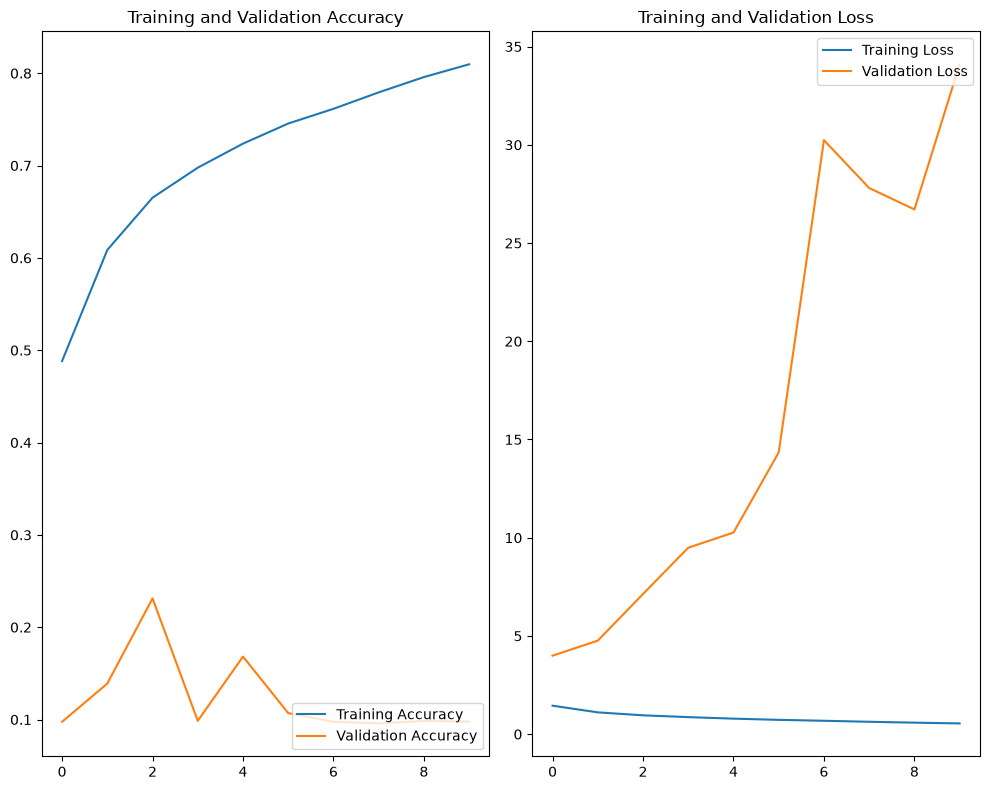

In [38]:
acc = m2.history['accuracy']
val_acc = m2.history['val_accuracy']

loss = m2.history['loss']
val_loss = m2.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(10, 8))

plt.subplot(1, 2, 1)

plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')

plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)

plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')

plt.legend(loc='upper right')
plt.title('Training and Validation Loss')

plt.tight_layout()
plt.savefig('./cifar10_training.png')
plt.show()

In [39]:
joblib.dump(model,'cnn_model.joblib')

['cnn_model.joblib']

In [45]:
try:
    model = joblib.load("cifar10_model.joblib")
except:
    pass

img = load_img(
    'horse.jpg',
    color_mode='rgb',
    target_size=(32, 32)
)

img = img_to_array(img)

img = img.astype('float32')
img = img / 255.0

img = img.reshape(1, 32, 32, 3)

pred_image = model.predict(img)

print("Predicted Class:", class_names[np.argmax(pred_image)])
print("Confidence:", np.max(pred_image))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step
Predicted Class: Horse
Confidence: 1.0
